In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("spotgentrack_clean.csv")
print(len(df))            
train = df[df["split"] == "train"]
print(len(train))          

101572
71065


In [3]:
num = ["popularity", "acousticness", "danceability", "energy", "instrumentalness",
       "liveness", "loudness", "speechiness", "tempo", "valence", "log_duration",
       "track_number", "disc_number", "artist_popularity", "log_followers",
       "total_tracks", "release_year"]

In [4]:
stats = pd.DataFrame({
    "mean":      train[num].mean(),
    "median":    train[num].median(),
    "sd":        train[num].std(),
    "min":       train[num].min(),
    "max":       train[num].max(),
    "skew":      train[num].skew(),
    "missing_%": train[num].isna().mean() * 100,
}).round(3)
stats

,mean,median,sd,min,max,skew,missing_%
popularity,39.873,41.000,16.713,0.000,97.000,-0.144,0.0
acousticness,0.352,0.237,0.335,0.000,0.996,0.587,0.0
danceability,0.589,0.612,0.174,0.054,0.989,-0.562,0.0
energy,0.588,0.630,0.259,0.000,1.000,-0.506,0.0
instrumentalness,0.148,0.000,0.303,0.000,1.000,1.824,0.0
liveness,0.197,0.124,0.175,0.012,0.999,2.271,0.0
loudness,-9.400,-7.586,6.052,-60.000,2.719,-1.905,0.0
speechiness,0.128,0.051,0.202,0.022,0.969,3.033,0.0
tempo,118.780,118.148,29.394,31.689,242.318,0.439,0.0
valence,0.485,0.480,0.261,0.000,0.993,0.060,0.0


In [5]:
print(train["pop_class"].value_counts(normalize=True).mul(100).round(1))
genre_cols = [c for c in train.columns if c.startswith("genre_broad_")]
print(train[genre_cols].mean().mul(100).round(1).sort_values(ascending=False))

pop_class
Low       49.9
Medium    39.4
High      10.7
Name: proportion, dtype: float64
genre_broad_unknown       18.4
genre_broad_other         13.6
genre_broad_rock          12.4
genre_broad_latin         12.3
genre_broad_hiphop_rap    10.3
genre_broad_pop            7.7
genre_broad_folk_indie     6.0
genre_broad_electronic     5.1
genre_broad_rnb_soul       4.7
genre_broad_metal          3.5
genre_broad_classical      3.1
genre_broad_jazz_blues     1.9
genre_broad_country        1.1
dtype: float64


In [6]:
stats.to_csv("r2_summary_stats.csv")

### Summary stats (train set, 71,065 tracks)
- No missing values anywhere.
- Popularity: mean 39.9, median 41, SD 16.7. Pretty symmetric (skew −0.14).
- Followers were really skewed (9.5). After log(1 + x) it's −0.20, so the log transform did its job.
- track_number (9.8), total_tracks (15.3) and disc_number (104.6) are still very skewed because of a few huge compilations. Trees won't care, but I'll standardise or log these for k-NN and the MLP.
- speechiness (3.0) and liveness (2.3) are right-skewed, which makes sense since most songs have barely any talking or crowd noise.
- release_year: median 2017 but mean 2012, so most tracks are recent with a long tail of older ones.
- Classes (train): Low 49.9%, Medium 39.4%, High 10.7%. High is the small class, so I'm using stratified splits and will report precision/recall/F-measure per class.
- Genres (train): unknown is 18.4% and other is 13.6%, so for about a third of tracks the genre is missing or too niche to be useful. That's a limitation of the genre feature.

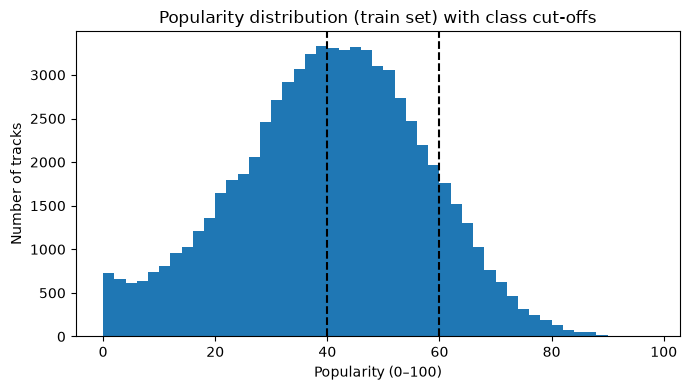

In [8]:
import matplotlib.pyplot as plt
import os
os.makedirs("figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(train["popularity"], bins=np.arange(0, 100, 2))
for cut in [40, 60]:
    ax.axvline(cut, linestyle="--", color="black")
ax.set_xlabel("Popularity (0–100)")
ax.set_ylabel("Number of tracks")
ax.set_title("Popularity distribution (train set) with class cut-offs")
fig.tight_layout()
fig.savefig("figures/fig1_popularity_hist.png", dpi=200)
plt.show()

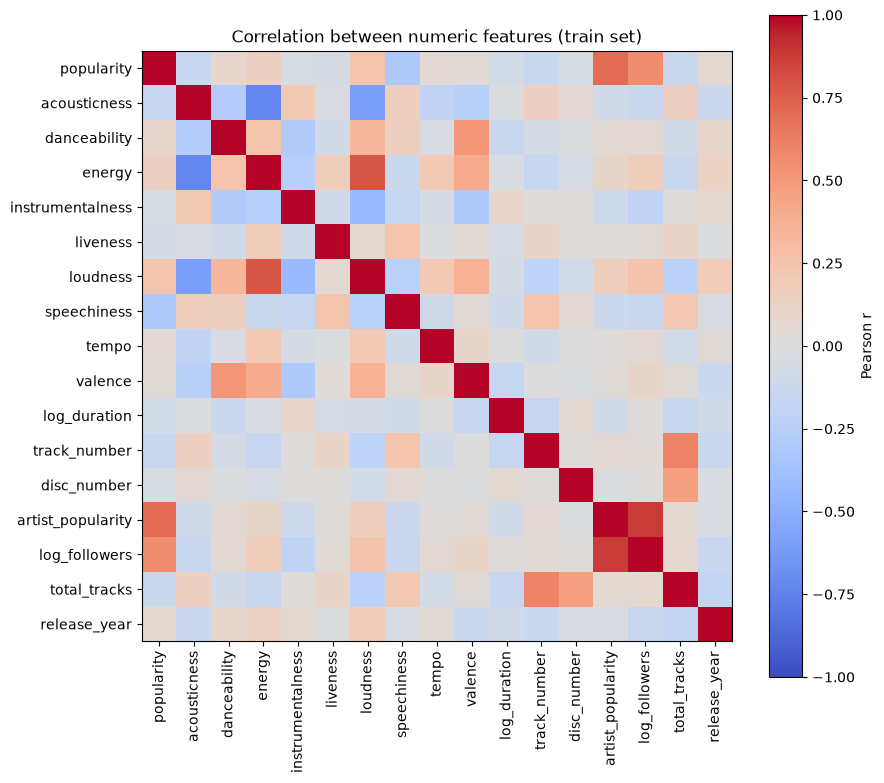

artist_popularity    0.702
log_followers        0.555
speechiness         -0.305
loudness             0.242
acousticness        -0.148
energy               0.147
track_number        -0.136
total_tracks        -0.127
danceability         0.079
log_duration        -0.068
liveness            -0.059
release_year         0.054
disc_number         -0.047
instrumentalness    -0.045
tempo                0.044
valence              0.025
Name: popularity, dtype: float64


In [9]:
corr = train[num].corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num)))
ax.set_xticklabels(num, rotation=90)
ax.set_yticks(range(len(num)))
ax.set_yticklabels(num)
fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Correlation between numeric features (train set)")
fig.tight_layout()
fig.savefig("figures/fig2_correlation.png", dpi=200)
plt.show()

print(corr["popularity"].drop("popularity").sort_values(key=abs, ascending=False).round(3))

In [10]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(pairs.drop(labels="popularity", level=0).sort_values(key=abs, ascending=False).head(6).round(3))

artist_popularity  log_followers    0.875
energy             loudness         0.785
acousticness       energy          -0.720
                   loudness        -0.598
track_number       total_tracks     0.596
danceability       valence          0.514
dtype: float64


### Correlations (train set)
- Popularity is mostly about the artist. artist_popularity (r = 0.70) and log_followers (0.56) are way ahead of everything else.
- The best audio feature is speechiness (−0.31), then loudness (0.24). Everything else is weak (|r| < 0.15), so how a song sounds won't predict popularity much on its own.
- A few features basically overlap: artist_popularity and log_followers (0.88), energy and loudness (0.79), acousticness and energy (−0.72), acousticness and loudness (−0.60), track_number and total_tracks (0.60), danceability and valence (0.51). These pairs are redundant, meaning one already carries most of the other's information, so they matter for feature selection and for the linear models.
- artist_popularity and log_followers at 0.88 are nearly the same thing, so it's worth checking whether we need both.
- That's also why we're running the models with and without the artist features.